In [38]:
import os
import pickle
import pandas as pd
from pathlib import Path

# ------------------------------------------------------------
# Paths
# ------------------------------------------------------------

MI_BASE = Path(
    "/fast/AG_Metzger/philipp/python_files/gene_signature/"
    "mutual_information_approach/November_25_ReDo/calc_files/MI/"
    "mi_analysis_results_MI_label_entropy_all_genes_parallel"
)

file_dict = {
    "weinreb": "/fast/AG_Metzger/philipp/python_files/gene_signature/mutual_information_approach/November_25_ReDo/preprocessing/pkl_files_filtered/weinreb_all_genes.pkl",
    "treutlein": "/fast/AG_Metzger/philipp/python_files/gene_signature/mutual_information_approach/November_25_ReDo/preprocessing/pkl_files_filtered/treutlein_all_genes.pkl",
    "junker": "/fast/AG_Metzger/philipp/python_files/gene_signature/mutual_information_approach/November_25_ReDo/preprocessing/pkl_files_filtered/junker_z5_all_genes.pkl",

    "knoblich_day16_1": "/fast/AG_Metzger/philipp/python_files/gene_signature/mutual_information_approach/November_25_ReDo/preprocessing/pkl_files_filtered/knoblich_day16_1.pkl",
    "knoblich_day16_2": "/fast/AG_Metzger/philipp/python_files/gene_signature/mutual_information_approach/November_25_ReDo/preprocessing/pkl_files_filtered/knoblich_day16_2.pkl",
    "knoblich_day42_1": "/fast/AG_Metzger/philipp/python_files/gene_signature/mutual_information_approach/November_25_ReDo/preprocessing/pkl_files_filtered/knoblich_day42_1.pkl",
    "knoblich_day42_2": "/fast/AG_Metzger/philipp/python_files/gene_signature/mutual_information_approach/November_25_ReDo/preprocessing/pkl_files_filtered/knoblich_day42_2.pkl",

    "you1": "/fast/AG_Metzger/philipp/python_files/gene_signature/mutual_information_approach/November_25_ReDo/preprocessing/pkl_files_filtered/you_stage1_barcode_all_genes.pkl",
    "you2": "/fast/AG_Metzger/philipp/python_files/gene_signature/mutual_information_approach/November_25_ReDo/preprocessing/pkl_files_filtered/you_stage2_barcode_all_genes.pkl",
    "you3": "/fast/AG_Metzger/philipp/python_files/gene_signature/mutual_information_approach/November_25_ReDo/preprocessing/pkl_files_filtered/you_stage3_barcode_all_genes.pkl",
    "you4": "/fast/AG_Metzger/philipp/python_files/gene_signature/mutual_information_approach/November_25_ReDo/preprocessing/pkl_files_filtered/you_stage4_barcode_all_genes.pkl",

    "morris_rna": "/fast/AG_Metzger/philipp/python_files/gene_signature/mutual_information_approach/November_25_ReDo/preprocessing/pkl_files_filtered/morris_RNA.pkl",
    "morris_atac": "/fast/AG_Metzger/philipp/python_files/gene_signature/mutual_information_approach/November_25_ReDo/preprocessing/pkl_files_filtered/morris_ATAC.pkl",
}


In [33]:
# Unified base path
base_path = "/fast/AG_Metzger/philipp/python_files/gene_signature/mutual_information_approach/November_25_ReDo/calc_files/MI/mi_analysis_results_MI_label_entropy_all_genes_parallel"

dataframes = {
    "knoblich_day16_1": pd.read_csv(f"{base_path}/MI_label_entropy_knoblich_day16_1_50_permutations.csv"),
    "knoblich_day16_2": pd.read_csv(f"{base_path}/MI_label_entropy_knoblich_day16_2_50_permutations.csv"),
    "knoblich_day42_1": pd.read_csv(f"{base_path}/MI_label_entropy_knoblich_day42_1_50_permutations.csv"),
    "knoblich_day42_2": pd.read_csv(f"{base_path}/MI_label_entropy_knoblich_day42_2_50_permutations.csv"),

    "weinreb": pd.read_csv(f"{base_path}/MI_label_entropy_weinreb_50_permutations.csv"),
    "treutlein": pd.read_csv(f"{base_path}/MI_label_entropy_treutlein_50_permutations.csv"),
    "junker": pd.read_csv(f"{base_path}/MI_label_entropy_junker_50_permutations.csv"),

    "you1": pd.read_csv(f"{base_path}/MI_label_entropy_you1_50_permutations.csv"),
    "you2": pd.read_csv(f"{base_path}/MI_label_entropy_you2_50_permutations.csv"),
    "you3": pd.read_csv(f"{base_path}/MI_label_entropy_you3_50_permutations.csv"),
    "you4": pd.read_csv(f"{base_path}/MI_label_entropy_you4_50_permutations.csv"),
}

In [12]:
import numpy as np
import pandas as pd


def find_distinct_lineages_fast(
    df,
    genename,
    n_lineages=4,
    min_cells_per_lineage=10,
    q_low=0.10,
    q_high=0.90,
    min_quantile_gap=0.0,
):
    """
    Fast selection of lineages with distinct expression levels.

    Instead of testing all combinations, this sorts lineages by median expression
    and selects approximately evenly spaced expression levels.
    """

    # Filter lineages with enough cells
    lineage_counts = df["barcode_cont"].value_counts()
    valid_lineages = lineage_counts[lineage_counts >= min_cells_per_lineage].index

    df_valid = df[df["barcode_cont"].isin(valid_lineages)].copy()

    # Compute robust summary per lineage
    summary = (
        df_valid
        .groupby("barcode_cont")[genename]
        .agg(
            n_cells="count",
            median="median",
            q_low=lambda x: x.quantile(q_low),
            q_high=lambda x: x.quantile(q_high),
            mean="mean"
        )
        .reset_index()
    )

    summary = summary.replace([np.inf, -np.inf], np.nan).dropna()
    summary = summary.sort_values("median").reset_index(drop=True)

    # Remove lineages with no expression variation if desired
    summary = summary[summary["q_high"] > summary["q_low"]].copy()
    summary = summary.reset_index(drop=True)

    if len(summary) < n_lineages:
        raise ValueError("Not enough valid lineages after filtering.")

    # Choose target expression positions across the median range
    target_medians = np.linspace(
        summary["median"].min(),
        summary["median"].max(),
        n_lineages
    )

    selected_rows = []
    used_indices = set()

    for target in target_medians:
        tmp = summary.copy()
        tmp["dist_to_target"] = np.abs(tmp["median"] - target)

        # avoid picking same lineage twice
        tmp = tmp[~tmp.index.isin(used_indices)]

        best_idx = tmp["dist_to_target"].idxmin()
        selected_rows.append(summary.loc[best_idx])
        used_indices.add(best_idx)

    selected = pd.DataFrame(selected_rows).sort_values("median").reset_index(drop=True)

    # Optional: check robust gaps between selected lineages
    selected["next_q_low"] = selected["q_low"].shift(-1)
    selected["gap_to_next"] = selected["next_q_low"] - selected["q_high"]

    selected_lineages = selected["barcode_cont"].astype(int).tolist()

    return selected_lineages, selected, summary

In [49]:
genename = "TUBB2B"

selected_lineages, selected_summary, all_summary = find_distinct_lineages_fast(
    treutlein,
    genename=genename,
    n_lineages=4,
    min_cells_per_lineage=10,
    q_low=0.10,
    q_high=0.90
)

selected_lineages

[2492, 194, 1231, 979]

In [50]:
selected_summary

,barcode_cont,n_cells,median,q_low,q_high,mean,next_q_low,gap_to_next
0,2492.0,85.0,0.000000,0.000000,1.685441,0.551251,0.043225,-1.642216
1,194.0,52.0,1.709741,0.043225,3.409195,1.766499,2.149570,-1.259625
2,1231.0,39.0,3.042917,2.149570,3.467662,2.837184,4.054503,0.586841
3,979.0,10.0,4.564333,4.054503,4.816963,4.461362,NaN,NaN


In [61]:


with open(file_dict["treutlein"], 'rb') as file:
    # Load the DataFrame from the pickle file
    treutlein = pickle.load(file)

In [63]:
treutlein["barcode_plot"] = treutlein["barcode_cont"].astype(str)

In [64]:
treutlein

x,FO538757.2,AP006222.2,LINC00115,FAM41C,SAMD11,NOC2L,KLHL17,PLEKHN1,HES4,ISG15,...,AP001469.7,AC136352.5,AC145212.4,AC145212.2,AC007325.2,AL354822.1,eGFP,Tomato,barcode_cont,barcode_plot
0,0.000000,1.262945,0.000000,0.000000,0.000000,0.0,0.000000,0.0,1.262945,0.000000,...,0.0,0.0,0.0,0.0,0.0,0.000000,0.000000,3.271779,0,0
1,0.000000,1.314547,0.000000,0.000000,0.000000,0.0,0.000000,0.0,2.215849,0.000000,...,0.0,0.0,0.0,0.0,0.0,0.000000,0.000000,2.998800,1,1
2,0.000000,0.000000,0.790053,0.000000,1.225840,0.0,0.790053,0.0,2.363503,0.790053,...,0.0,0.0,0.0,0.0,0.0,0.790053,0.000000,2.655961,2,2
3,1.117912,0.000000,0.000000,0.000000,1.117912,0.0,0.000000,0.0,1.117912,0.000000,...,0.0,0.0,0.0,0.0,0.0,0.000000,0.000000,2.222875,3,3
4,0.000000,0.560077,0.000000,0.000000,0.000000,0.0,0.000000,0.0,2.375881,0.000000,...,0.0,0.0,0.0,0.0,0.0,0.000000,0.000000,2.863215,4,4
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
16501,0.000000,0.000000,0.000000,0.000000,0.000000,0.0,0.000000,0.0,1.006538,0.000000,...,0.0,0.0,0.0,0.0,0.0,0.000000,2.576633,0.000000,1108,1108
16502,0.000000,0.000000,0.000000,0.926092,0.000000,0.0,0.000000,0.0,0.000000,1.398530,...,0.0,0.0,0.0,0.0,0.0,0.000000,2.689316,0.000000,1108,1108
16503,0.000000,0.000000,0.000000,0.000000,0.000000,0.0,0.000000,0.0,0.000000,0.822562,...,0.0,0.0,0.0,0.0,0.0,0.000000,2.937496,0.000000,1108,1108
16504,0.812461,0.000000,1.254731,0.000000,0.000000,0.0,0.000000,0.0,0.812461,1.983376,...,0.0,0.0,0.0,0.0,0.0,0.000000,2.693810,0.000000,1108,1108


In [69]:
import matplotlib.pyplot as plt
import seaborn as sns

def plot_all_lineages_highlight_selected(
    df,
    genename,
    selected_lineages, 
    palette="Set2",
    min_cells_per_lineage=10,
    default_color="#ADD8E6",
    q75_filter=True,
    outname="TUBB2B_all_with_specific_lineages.pdf"
):
    df = df.copy()

    # Remove unused categories if barcode_cont is categorical
    if hasattr(df["barcode_cont"], "cat"):
        df["barcode_cont"] = df["barcode_cont"].cat.remove_unused_categories()

    # Filter lineages with enough cells
    lineage_counts = df["barcode_cont"].value_counts()
    valid_lineages = lineage_counts[lineage_counts >= min_cells_per_lineage].index
    df = df[df["barcode_cont"].isin(valid_lineages)].copy()

    # Remove unused categories again after filtering
    if hasattr(df["barcode_cont"], "cat"):
        df["barcode_cont"] = df["barcode_cont"].cat.remove_unused_categories()

    # Optional q75 > 0 filter, as in your working function
    if q75_filter:
        q75 = df.groupby("barcode_cont", observed=True)[genename].quantile(0.75)
        barcodes_to_consider = q75[q75 > 0].index
        df = df[df["barcode_cont"].isin(barcodes_to_consider)].copy()

        if hasattr(df["barcode_cont"], "cat"):
            df["barcode_cont"] = df["barcode_cont"].cat.remove_unused_categories()

    # Build color mapping
    selected_lineages = list(selected_lineages)
    colors = sns.color_palette(palette, n_colors=len(selected_lineages))
    color_map = dict(zip(selected_lineages, colors))

    # Critical: observed=True
    custom_order = (
        df.groupby("barcode_cont", observed=True)[genename]
        .median()
        .sort_values()
        .index
        .tolist()
    )

    full_palette = {
        bc: color_map.get(bc, default_color)
        for bc in custom_order
    }

    plt.figure(figsize=(10, 6))

    sns.boxplot(
        data=df,
        x="barcode_cont",
        y=genename,
        order=custom_order,
        palette=full_palette,
        linewidth=0.5,
        flierprops=dict(marker=".", markersize=2, linestyle="none")
    )

    plt.xticks([], [])
    plt.xlabel("")
    plt.ylabel(f"Expression {genename}")
    plt.title(
        f"{genename} expression across all lineages "
        f"(highlighted: {len(selected_lineages)})"
    )

    sns.despine()
    plt.tight_layout()
    plt.savefig(outname, bbox_inches="tight")
    plt.show()

    return full_palette, color_map, custom_order

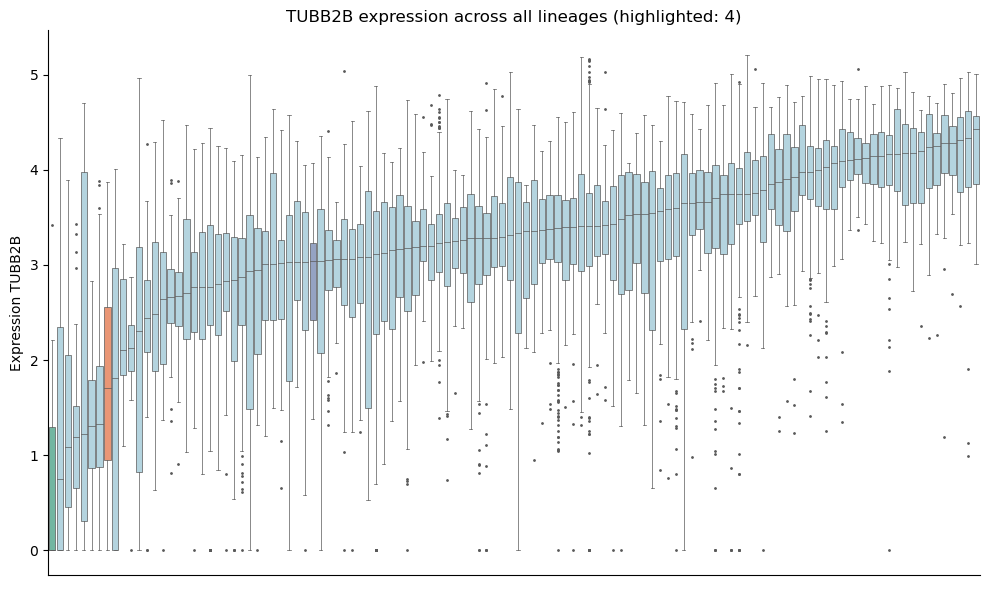

In [73]:
full_palette, color_map, custom_order = plot_all_lineages_highlight_selected(
    treutlein,
    genename="TUBB2B",
    selected_lineages=[2492, 194, 1231, 979],
    palette="Set2",
    min_cells_per_lineage=20,
    q75_filter=True,
    outname="TUBB2B_all_with_optimized_4_lineages.pdf"
)

In [74]:
import matplotlib.pyplot as plt
import seaborn as sns

def plot_selected_lineages_only(
    df,
    genename,
    selected_lineages,
    color_map,
    group_col="barcode_cont",
    outname="TUBB2B_in_selected_lineages.pdf"
):
    df = df.copy()

    # Keep only selected lineages
    df_selected = df[df[group_col].isin(selected_lineages)].copy()

    if df_selected.empty:
        raise ValueError("No cells found for selected_lineages. Check barcode types / IDs.")

    # Remove unused categories if barcode_cont is categorical
    if hasattr(df_selected[group_col], "cat"):
        df_selected[group_col] = df_selected[group_col].cat.remove_unused_categories()

    # Order selected lineages by median expression
    order = (
        df_selected
        .groupby(group_col, observed=True)[genename]
        .median()
        .sort_values(ascending=True)
        .index
        .tolist()
    )

    # Match colors to the order
    box_colors = [color_map[bc] for bc in order]

    plt.figure(figsize=(4, 3))

    flier_marker = dict(marker=".", markersize=2, linestyle="none")

    sns.boxplot(
        data=df_selected,
        y=genename,
        x=group_col,
        order=order,
        palette=box_colors,
        flierprops=flier_marker,
        linewidth=0.6
    )

    sns.stripplot(
        data=df_selected,
        y=genename,
        x=group_col,
        order=order,
        color="black",
        size=2,
        jitter=0.25,
        alpha=0.4
    )

    plt.ylabel(f"Expression {genename}")
    plt.xlabel("Lineage")
    plt.title(f"{genename} expression in selected lineages")

    sns.despine()
    plt.tight_layout()
    plt.savefig(outname, bbox_inches="tight")
    plt.show()

    return df_selected, order

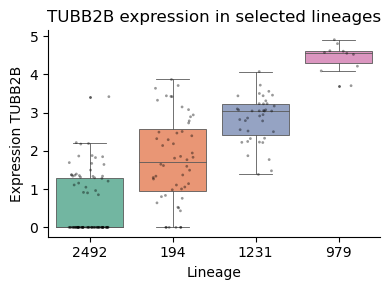

In [75]:
df_selected, order = plot_selected_lineages_only(
    treutlein,
    genename="TUBB2B",
    selected_lineages=selected_lineages,
    color_map=color_map,
    outname="TUBB2B_optimized_4_lineages.pdf"
)